# Introduction to cuisine classification

We explore all five cuisines, then reproduce the lesson’s SMOTE exercise on **training rows only**. Identical model-input vectors stay in the same split. Rice, garlic and ginger are removed to reproduce the lesson, not because common ingredients are necessarily uninformative. All results describe this dataset, not entire cultures.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

raw = pd.read_csv(Path("../../../4-Classification/data/cuisines.csv"))
X = raw.drop(columns=["cuisine", "Unnamed: 0", "rice", "garlic", "ginger"]).astype(float)
y = raw.cuisine
# Group identical feature vectors, even when their labels disagree.
groups = pd.util.hash_pandas_object(X, index=False)
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[test_idx]))
assert X.shape[1] == 380 and X.isin([0, 1]).all().all()
print(f"Rows: {len(X)}; train: {len(X_train)}; test: {len(X_test)}; features: {X.shape[1]}")


Rows: 2448; train: 1960; test: 488; features: 380


,Unnamed: 0,cuisine,almond,angelica,anise,anise_seed,apple,apple_brandy,apricot,armagnac,...,whiskey,white_bread,white_wine,whole_grain_wheat_flour,wine,wood,yam,yeast,yogurt,zucchini
0,65,indian,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,66,indian,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,67,indian,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,68,indian,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,69,indian,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0


(2448, 385)
int64     384
object      1
Name: count, dtype: int64
Missing values: 0


cuisine
korean      799
indian      598
chinese     442
japanese    320
thai        289
Name: count, dtype: int64

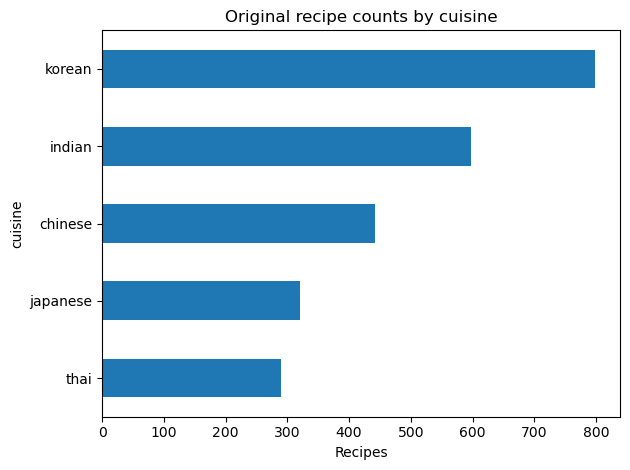

In [2]:
display(raw.head())
print(raw.shape)
print(raw.dtypes.value_counts())
print("Missing values:", int(raw.isna().sum().sum()))
display(raw.cuisine.value_counts())
raw.cuisine.value_counts().sort_values().plot.barh(title="Original recipe counts by cuisine")
plt.xlabel("Recipes")
plt.tight_layout()
plt.show()

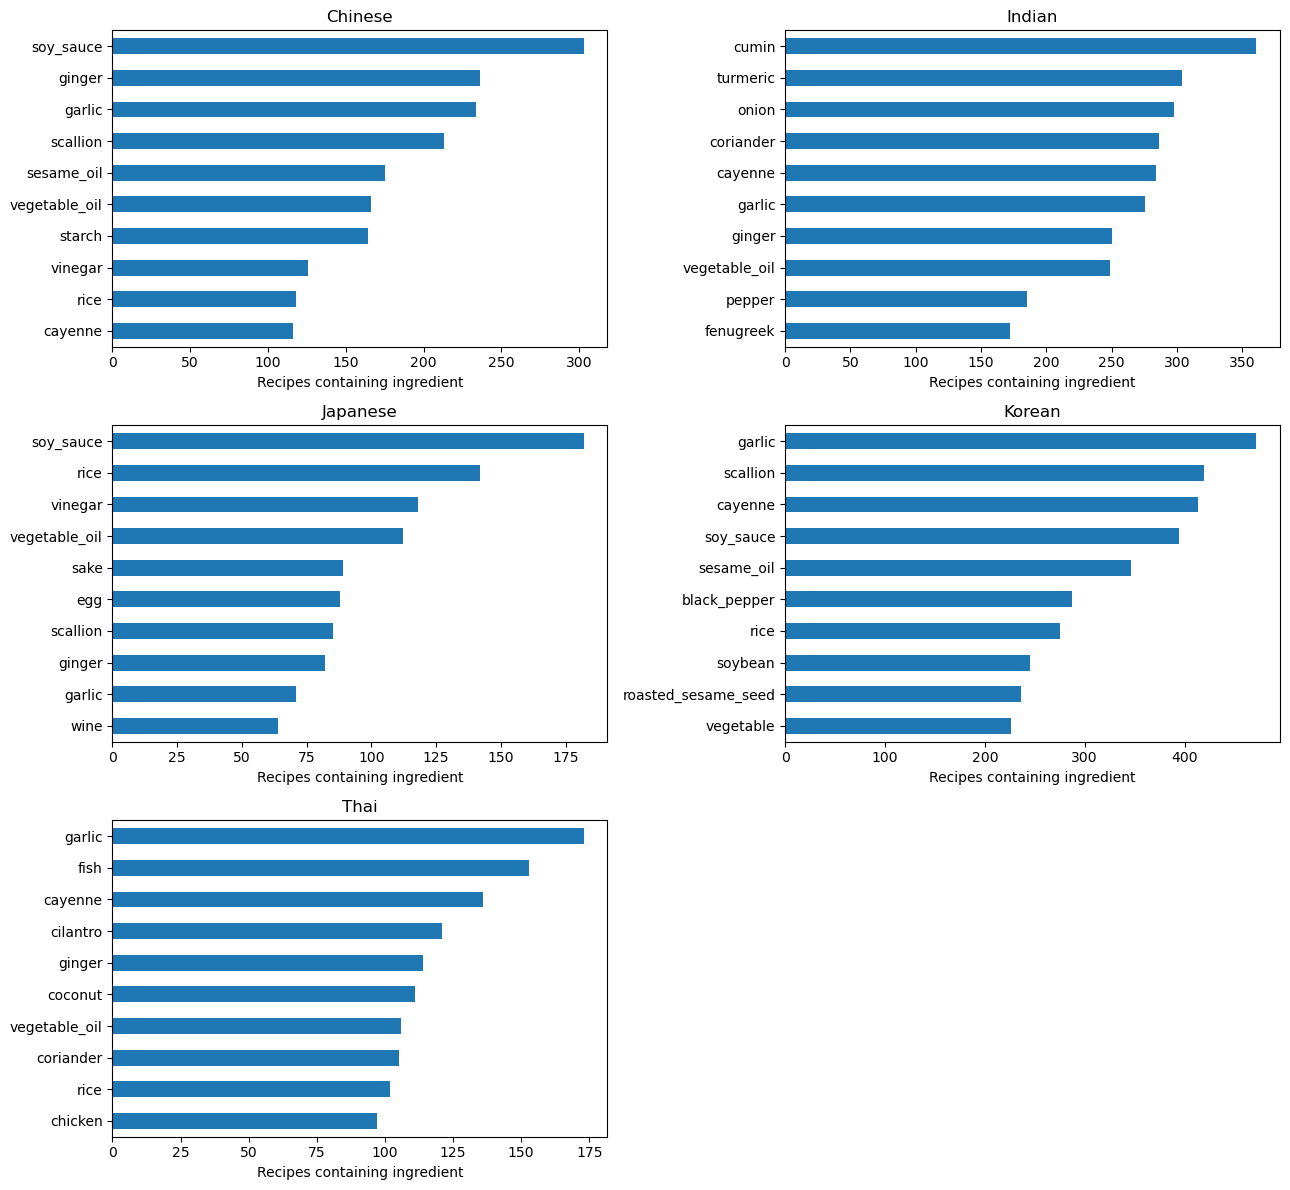

,rice,garlic,ginger,fenugreek
cuisine,,,,
chinese,0.267,0.529,0.534,0.009
indian,0.157,0.462,0.418,0.288
japanese,0.444,0.222,0.256,0.019
korean,0.344,0.591,0.282,0.004
thai,0.353,0.599,0.394,0.211


In [3]:
ingredients = raw.drop(columns=["cuisine", "Unnamed: 0"])
fig, axes = plt.subplots(3, 2, figsize=(13, 12))
for axis, cuisine in zip(axes.flat, sorted(y.unique())):
    counts = ingredients.loc[y == cuisine].sum().nlargest(10).sort_values()
    counts.plot.barh(ax=axis, title=cuisine.title())
    axis.set_xlabel("Recipes containing ingredient")
axes.flat[-1].axis("off")
fig.tight_layout()
plt.show()
# Within-cuisine prevalence allows comparisons across unequal sample sizes.
display(ingredients.groupby(y).mean()[["rice", "garlic", "ginger", "fenugreek"]].round(3))

## Balance the training data

SMOTE interpolates between nearby minority examples. Float features deliberately retain fractional values; these are synthetic points, not literal recipes. For binary ingredient flags, random oversampling or class weighting avoids inventing fractional ingredients. Balancing changes the training distribution and does not guarantee a better model.

,Before,After
cuisine,,
chinese,354,647
indian,474,647
japanese,259,647
korean,647,647
thai,226,647


Fractional synthetic feature entries: 8440


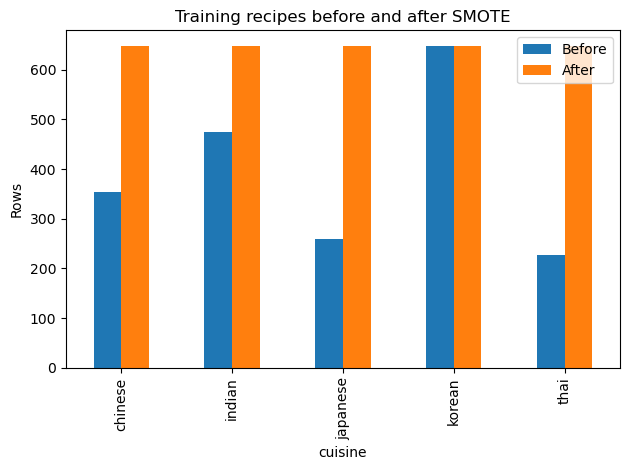

Saved training-balanced.csv and untouched held-out.csv locally.


In [4]:
from imblearn.over_sampling import SMOTE
sampler = SMOTE(random_state=42)
X_balanced, y_balanced = sampler.fit_resample(X_train, y_train)
counts = pd.DataFrame({"Before": y_train.value_counts(), "After": y_balanced.value_counts()}).fillna(0).astype(int)
display(counts)
assert counts.After.nunique() == 1
assert X_balanced.shape[1] == X_test.shape[1]
assert X_balanced.to_numpy().min() >= 0 and X_balanced.to_numpy().max() <= 1
print("Fractional synthetic feature entries:", int(((X_balanced > 0) & (X_balanced < 1)).sum().sum()))
counts.plot.bar(title="Training recipes before and after SMOTE")
plt.ylabel("Rows")
plt.tight_layout()
plt.show()
pd.concat([y_balanced.rename("cuisine"), X_balanced], axis=1).to_csv("training-balanced.csv", index=False)
pd.concat([y_test, X_test], axis=1).to_csv("held-out.csv", index=False)
assert len(pd.read_csv("held-out.csv")) == len(test_idx)
print("Saved training-balanced.csv and untouched held-out.csv locally.")

## Knowledge checks and challenge

A multiclass target asks which of five cuisine labels best matches an ingredient vector. A binary target could ask whether a recipe contains fenugreek; that ingredient must then be excluded from inputs. Classifying a grocery basket does not prove a dish is authentic or feasible. Other curriculum tasks include binary pumpkin color (orange versus other), multiclass UFO reporting country, and binary restaurant-review sentiment. Each requires labeled examples and a metric sensitive to minority-class errors.

SMOTE is intended for imbalanced classification where meaningful distances and interpolation exist. It requires enough examples for its neighbor count and may amplify noise near overlapping classes. Use it inside each training fold, never on the full dataset before splitting. See the linked API discussion in answers.md.